# Trajectory profiling reports

Analyze existing Scalene profiles and library traces for Spaceship Titanic, House Price, NYC Housing, and NYC Taxi. This notebook does **not** execute or train pipelines.

All category calculations come from `scripts/report_categories.py`; hotspot calculations and labels come from `scripts/report_hotspot.py`. Run all cells to regenerate CSVs and plots. Each trajectory gets its own figure so labels remain readable.

In [1]:
%matplotlib inline

import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts/report_hotspot.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts import report_categories, report_hotspot

TRAJECTORIES = [
    "spaceship_titanic_students",
    "house_price_students",
    "nyc_housing_students",
    "nyc_taxi_students",
]
TOP_N = 10


## Input coverage

Require one profile and one library trace for every pipeline in each manifest. Interrupted-run backups ending in `.json.bak` are excluded. File coverage alone cannot establish that a run finished; these datasets were checked against completion logs before analysis.

In [2]:
coverage = []
for name in TRAJECTORIES:
    manifest = json.loads((ROOT / "trajectories" / name / "trajectory.json").read_text())
    expected = {Path(p["file"]).stem for step in manifest["steps"] for p in step["pipelines"]}
    counts = {}
    for kind in ("profiles", "libraries"):
        found = {p.stem for p in (ROOT / "profiling" / kind / name).glob("pipeline_*.json")}
        if found != expected:
            raise ValueError(f"{name}/{kind}: missing={sorted(expected - found)}, extra={sorted(found - expected)}")
        counts[kind] = len(found)
    coverage.append({"trajectory": name, "expected_pipelines": len(expected), **counts})
display(pd.DataFrame(coverage).set_index("trajectory"))


,expected_pipelines,profiles,libraries
trajectory,,,
spaceship_titanic_students,25,25,25
house_price_students,19,19,19
nyc_housing_students,20,20,20
nyc_taxi_students,20,20,20


## Category reports

Each pipeline is split into **setup**, **data handling**, **models**, and **other**, using the existing module-prefix rules. Unmatched non-import lines fall back to data handling; this is a heuristic, not a semantic classification of every library. Code outside the pipeline file is assigned to other.

`total_s` includes Python, native, and system estimates. CSV `share_of_runtime` uses elapsed profiled runtime as its denominator; the plot's percentage panel normalizes to the sum of attributed category time. Peaks are not additive and cannot directly determine concurrency limits. Allocation and copy quantities are volumes, not durations.

Outputs: `profiling/results/<trajectory>/categories.csv` and `categories.png`.

### spaceship_titanic_students

category,setup,data handling,models,other
pipeline,,,,
pipeline_1_1,1.434,0.165,0.375,0.000
pipeline_1_2,1.700,0.360,0.127,0.102
pipeline_1_3,1.260,0.452,0.000,0.051
pipeline_2_1,1.775,0.453,0.249,0.090
pipeline_2_2,1.590,0.419,0.102,0.055
pipeline_2_3,1.436,0.487,0.114,0.063
pipeline_3_1,1.288,0.523,0.088,0.027
pipeline_3_2,1.191,0.436,0.118,0.069
pipeline_3_3,1.393,0.522,0.114,0.059


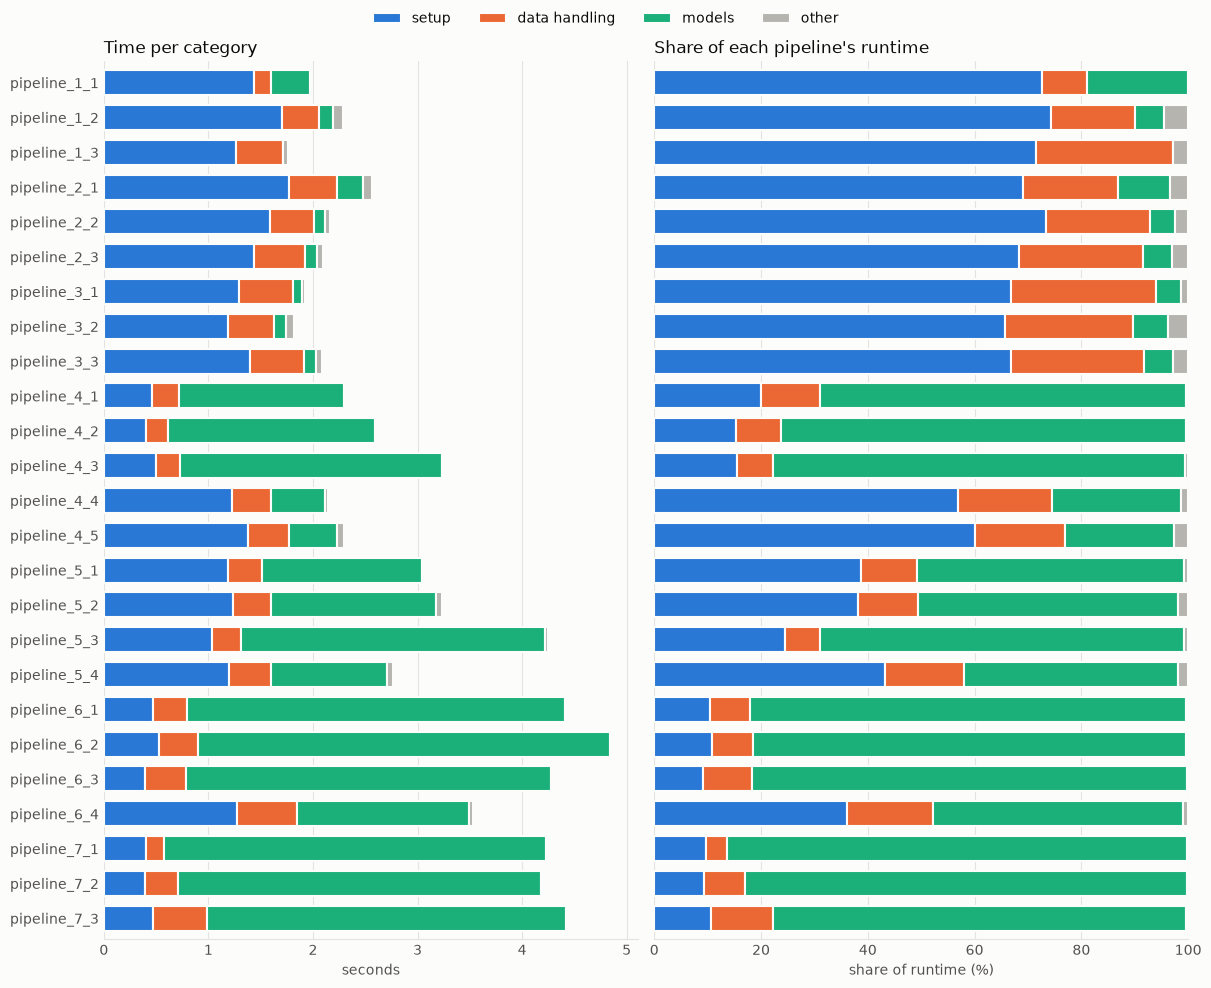

### house_price_students

category,setup,data handling,models,other
pipeline,,,,
pipeline_10_1,0.272,14.035,35.803,0.0
pipeline_11_1,0.678,96.445,261.297,0.0
pipeline_1_1,0.105,15.759,13.147,0.0
pipeline_1_2,0.431,16.310,8.146,0.0
pipeline_1_3,0.112,12.815,17.457,0.0
pipeline_2_1,0.138,15.187,11.621,0.0
pipeline_3_1,0.226,13.504,12.741,0.0
pipeline_3_2,0.319,12.132,18.425,0.0
pipeline_3_3,0.073,13.980,14.019,0.0


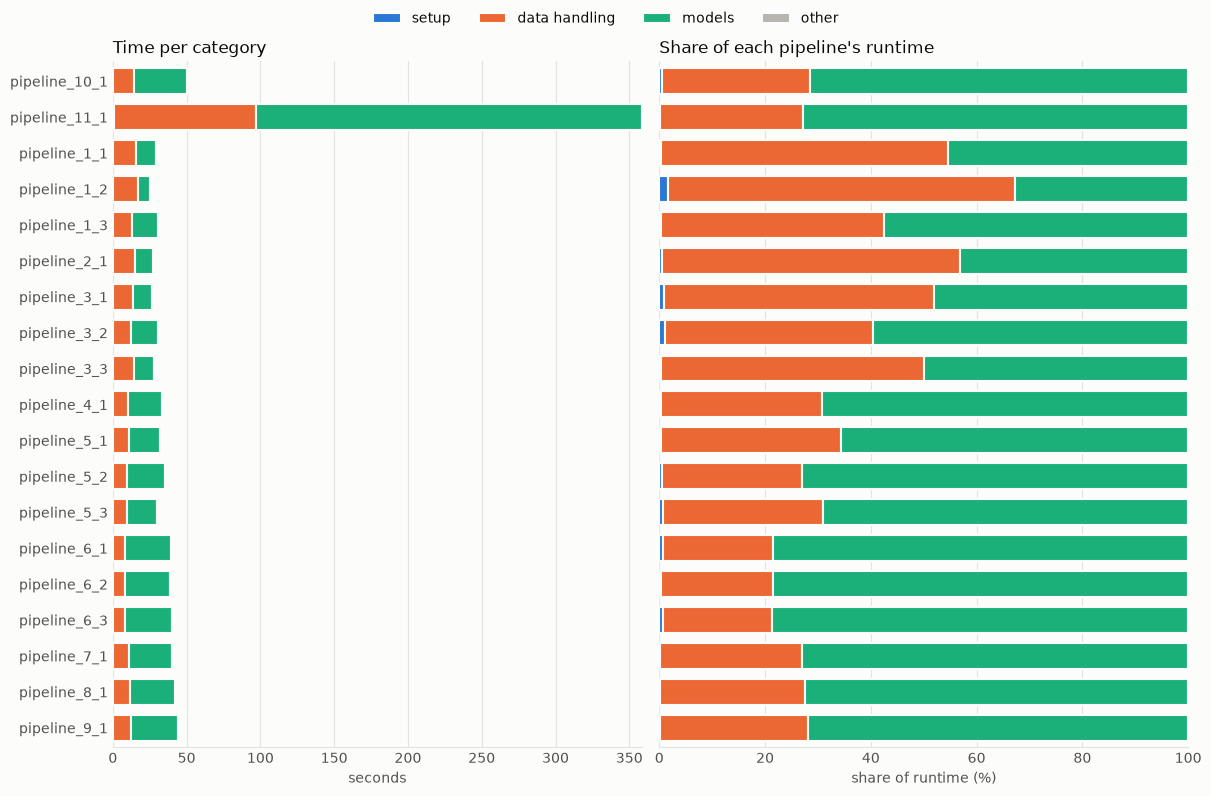

### nyc_housing_students

category,setup,data handling,models,other
pipeline,,,,
pipeline_10_1,0.266,44.620,1.484,0.138
pipeline_11_1,0.312,44.625,1.492,0.197
pipeline_12_1,0.524,57.732,1.849,0.209
pipeline_13_1,0.447,67.144,1.885,0.220
pipeline_14_1,0.236,64.943,1.938,0.197
pipeline_15_1,0.464,69.498,1.960,0.223
pipeline_16_1,0.405,81.533,2.010,0.267
pipeline_17_1,0.438,91.154,2.127,0.149
pipeline_18_1,0.240,64.170,1.747,0.091


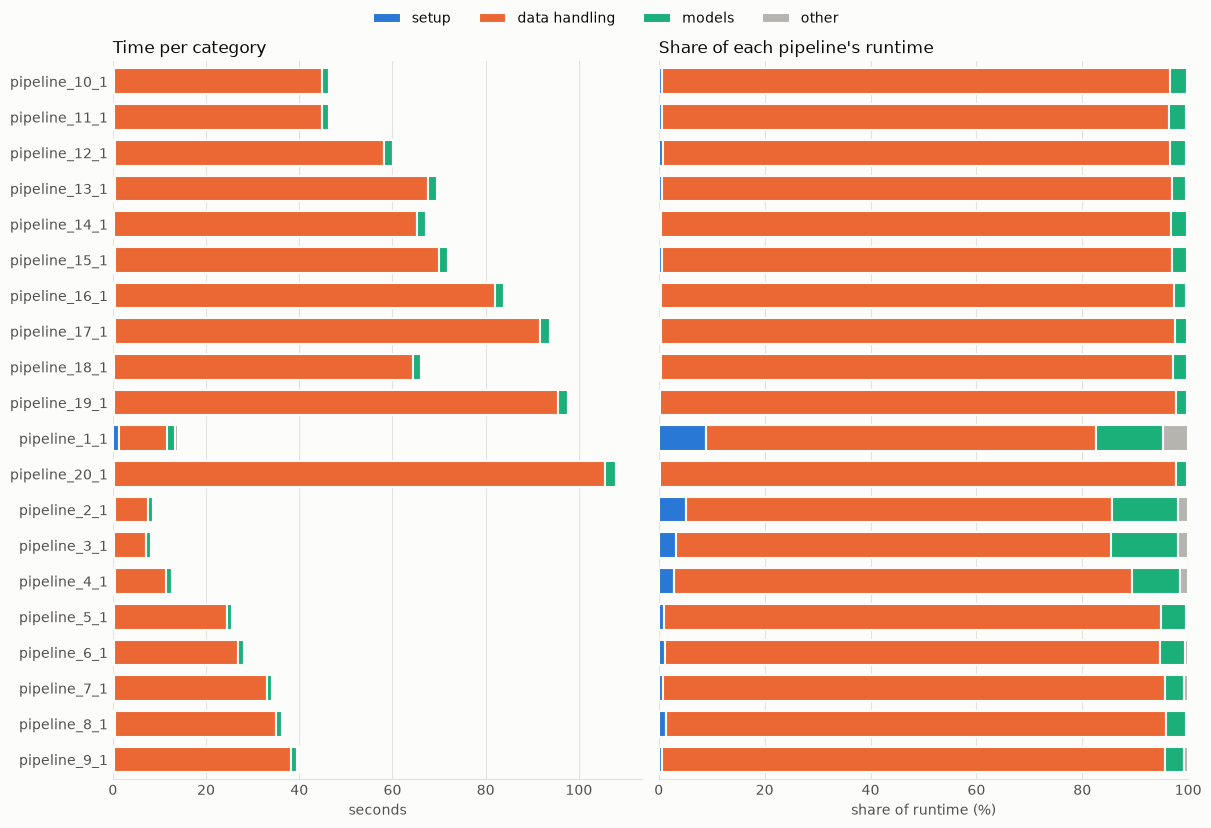

### nyc_taxi_students

category,setup,data handling,models,other
pipeline,,,,
pipeline_1_1,2.123,15.401,565.435,0.163
pipeline_1_2,2.009,16.443,210.077,0.213
pipeline_1_3,2.022,15.695,1372.340,0.179
pipeline_2_1,2.365,4.155,670.683,0.103
pipeline_2_2,6.317,17.528,1247.822,0.458
pipeline_2_3,1.890,4.333,1630.187,0.151
pipeline_3_1,2.733,35.906,919.858,0.117
pipeline_3_2,2.888,35.863,872.661,0.134
pipeline_3_3,0.767,14.946,2376.807,0.014


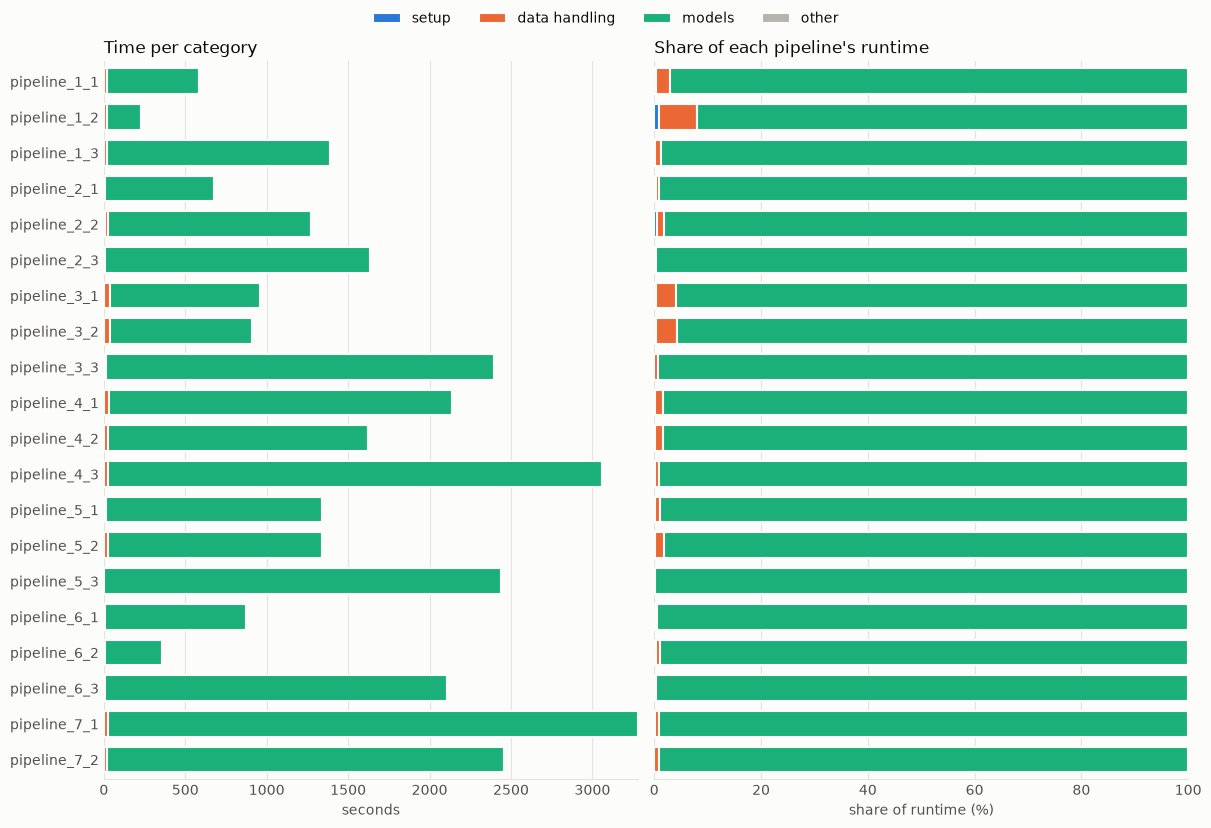

In [3]:
categories_by_trajectory = {}
for name in TRAJECTORIES:
    totals = report_categories.analyze_trajectory(name)
    categories_by_trajectory[name] = totals
    output_dir = ROOT / "profiling/results" / name
    output_dir.mkdir(parents=True, exist_ok=True)
    totals.to_csv(output_dir / "categories.csv", index=False)
    display(Markdown(f"### {name}"))
    display(totals.pivot(index="pipeline", columns="category", values="total_s")
            [report_categories.CATEGORIES].round(3))
    fig = report_categories.plot(totals, output_dir / "categories.png")
    display(fig)
    plt.close(fig)


## Top 10 hotspots across each trajectory

Statements are grouped by their full source text after removing indentation and decoding Scalene Unicode escapes. Different parameters or variable names remain separate. Short plot labels are for display only; they do not change grouping. Identical statements can represent different models or inputs and do not establish cacheability.

Only lines in each pipeline file are ranked. Function timings are not added to line timings. Python, native, and system estimates are retained; other files and unattributed residual time are reported separately. Percentages use summed profiled runtime, not unprofiled benchmark time.

Outputs: `results/<trajectory>/hotspots.csv` (full ranking), `hotspots_details.csv` (all locations behind Top N), and `hotspots.png`.

### spaceship_titanic_students

[spaceship_titanic_students] Profiles: 25; summed profiled runtime: 75.07 s
[spaceship_titanic_students] Pipeline source attribution: 73.64 s
[spaceship_titanic_students] Other files + unattributed residual: 1.43 s
[spaceship_titanic_students] Top 10: 67.24 s (89.6% of summed runtime)


,rank,operation,python_s,native_s,system_s,total_s,n_pipelines,n_source_locations,n_timed_locations,share_of_runs_pct,cumulative_share_pct
0,1,"classifier.fit(X_train_fold, y[fit_rows])",12.369,21.974,1.911,36.254,25,37,36,48.293,48.293
1,2,from sklearn.compose import ColumnTransformer,7.259,6.355,1.934,15.548,25,25,25,20.711,69.005
2,3,import pandas as pd,2.490,4.791,1.056,8.338,25,25,24,11.106,80.111
3,4,X_train_fold = preprocessor.fit_transform(X.il...,0.854,1.900,0.124,2.878,25,37,37,3.833,83.944
4,5,X_val_fold = preprocessor.transform(X.iloc[hol...,0.296,0.465,0.020,0.781,25,37,27,1.040,84.985
5,6,X_test_fold = preprocessor.transform(X_test),0.266,0.485,0.013,0.764,25,37,24,1.018,86.002
6,7,test_0 = classifier.predict_proba(X_test_fold)...,0.327,0.334,0.058,0.719,25,25,10,0.957,86.960
7,8,manifest['Family_Size'] = manifest['Surname']....,0.029,0.666,0.019,0.714,25,25,7,0.952,87.911
8,9,from sklearn.impute import SimpleImputer,0.294,0.272,0.066,0.632,25,25,14,0.841,88.753
9,10,manifest['Group_MeanSpend'] = manifest.groupby...,0.039,0.554,0.020,0.613,25,25,12,0.817,89.569


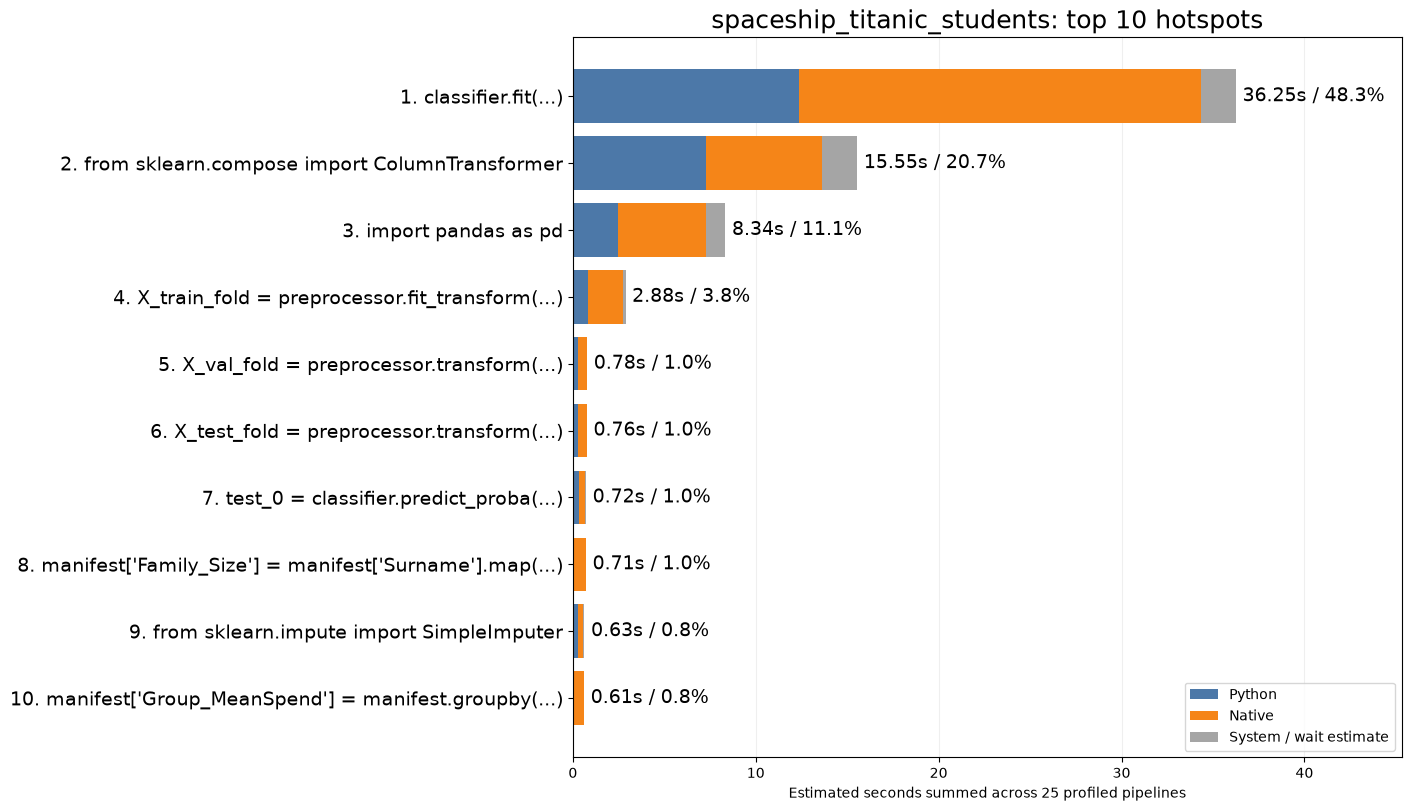

### house_price_students

[house_price_students] Profiles: 19; summed profiled runtime: 980.79 s
[house_price_students] Pipeline source attribution: 980.62 s
[house_price_students] Other files + unattributed residual: 0.17 s
[house_price_students] Top 10: 816.72 s (83.3% of summed runtime)


,rank,operation,python_s,native_s,system_s,total_s,n_pipelines,n_source_locations,n_timed_locations,share_of_runs_pct,cumulative_share_pct
0,1,lgb_val_model = lgb.train(,226.045,184.716,1.851,412.613,19,19,19,42.069,42.069
1,2,xgb_val_model.fit(,103.845,57.117,2.995,163.957,5,5,5,16.717,58.786
2,3,df_train = pd.read_csv(DATA_PATH).rename(,13.136,59.171,12.721,85.028,19,19,19,8.669,67.455
3,4,cat_val_model.fit(,7.205,44.423,0.448,52.076,3,3,3,5.310,72.765
4,5,"df_train = df_train.sample(n=N_ROWS, random_st...",0.863,16.001,12.000,28.864,19,19,19,2.943,75.708
5,6,"grouped = calc_df.groupby(""grp"", sort=False).s...",13.083,3.919,10.968,27.970,19,38,38,2.852,78.560
6,7,y_res_hat = self.gbd_residual_model.predict(,2.419,10.495,0.222,13.137,11,11,11,1.339,79.899
7,8,df_train[col] = df_train[col].astype(str).str....,0.391,9.785,1.242,11.418,19,19,19,1.164,81.063
8,9,lgb_res = self.lgb_model.predict(,3.592,7.236,0.141,10.969,8,8,8,1.118,82.182
9,10,lgb_val_res_preds = lgb_val_model.predict(val_...,3.245,7.350,0.095,10.690,8,8,8,1.090,83.272


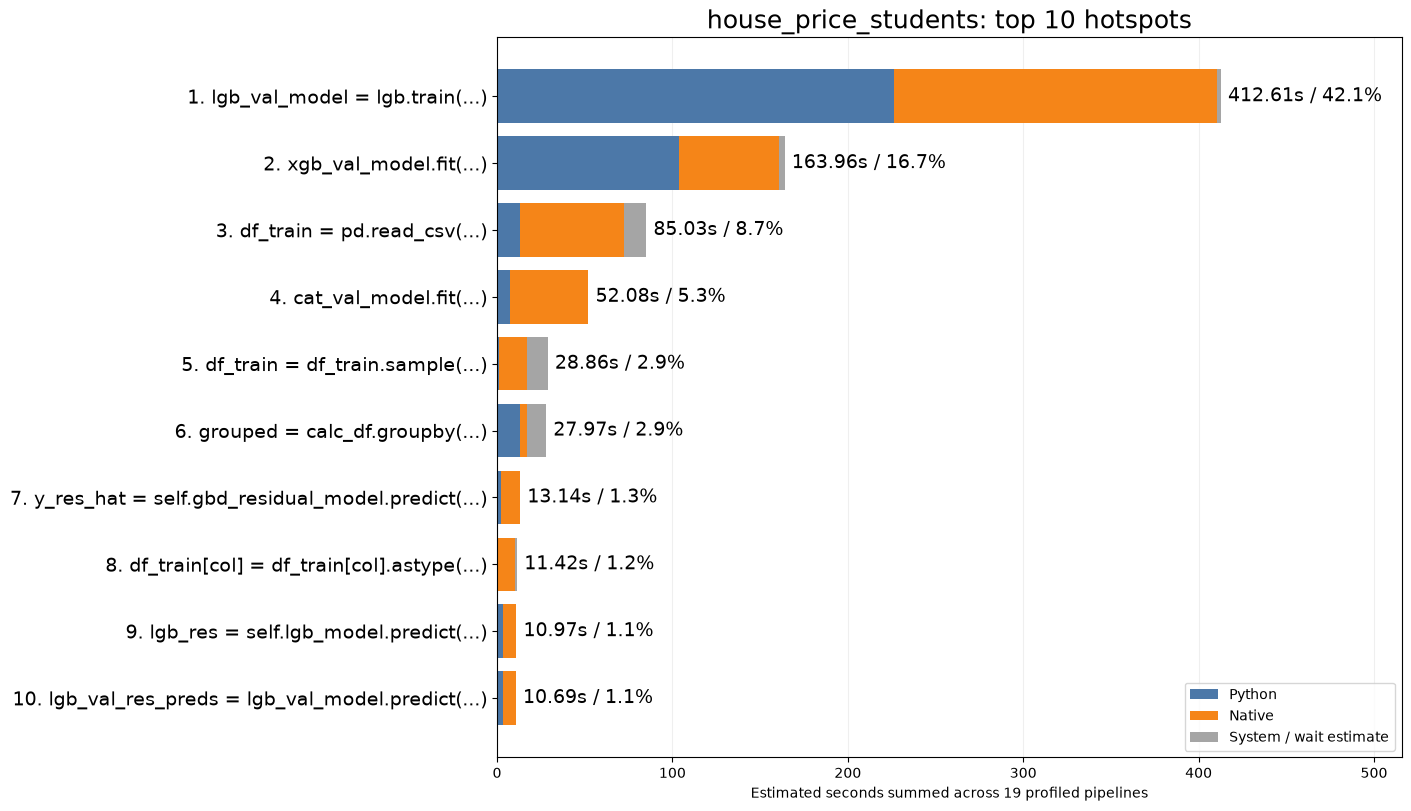

### nyc_housing_students

[nyc_housing_students] Profiles: 20; summed profiled runtime: 1022.09 s
[nyc_housing_students] Pipeline source attribution: 1017.52 s
[nyc_housing_students] Other files + unattributed residual: 4.56 s
[nyc_housing_students] Top 10: 340.84 s (33.3% of summed runtime)


,rank,operation,python_s,native_s,system_s,total_s,n_pipelines,n_source_locations,n_timed_locations,share_of_runs_pct,cumulative_share_pct
0,1,"df_comp = pd.read_parquet(complaint_path, colu...",0.457,29.226,60.026,89.709,18,18,18,8.777,8.777
1,2,"df_comp = df_comp.sample(frac=SAMPLE_FRACTION,...",1.457,33.926,14.097,49.481,18,18,18,4.841,13.618
2,3,"df_viol = pd.read_parquet(viol_path, columns=v...",0.449,33.244,5.539,39.232,19,19,19,3.838,17.457
3,4,if len(df_comp) > 0 and df_comp['event_dt'].no...,0.073,31.502,2.686,34.261,18,18,18,3.352,20.809
4,5,"model.fit(X_train, y_train)",4.405,24.135,1.477,30.017,20,20,20,2.937,23.745
5,6,s_up = df_comp[c_low].astype(str).str.upper(),1.926,23.966,3.677,29.569,15,15,15,2.893,26.639
6,7,paint_mask = paint_mask | s_up.str.contains('P...,1.322,15.640,0.682,17.644,12,12,12,1.726,28.365
7,8,leak_mask = leak_mask | s_up.str.contains('LEA...,1.590,14.811,0.772,17.173,12,12,12,1.680,30.045
8,9,"df_pluto = pd.read_parquet(pluto_path, columns...",0.452,15.546,0.966,16.965,19,19,19,1.660,31.705
9,10,"df_aux = pd.read_parquet(t_path, columns=keep)",1.093,15.213,0.481,16.787,19,19,18,1.642,33.347


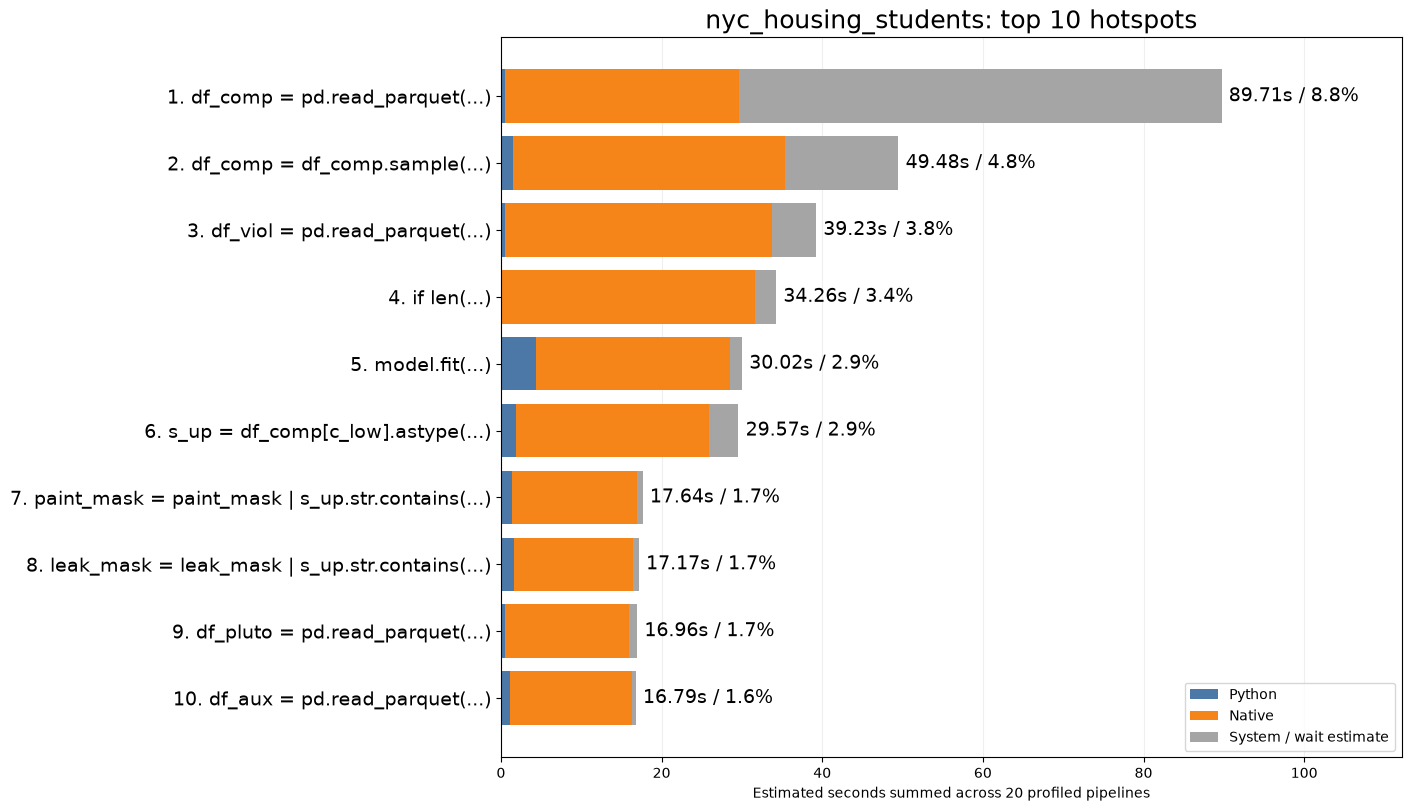

### nyc_taxi_students

[nyc_taxi_students] Profiles: 20; summed profiled runtime: 31055.13 s
[nyc_taxi_students] Pipeline source attribution: 31050.91 s
[nyc_taxi_students] Other files + unattributed residual: 4.22 s
[nyc_taxi_students] Top 10: 30987.39 s (99.8% of summed runtime)


,rank,operation,python_s,native_s,system_s,total_s,n_pipelines,n_source_locations,n_timed_locations,share_of_runs_pct,cumulative_share_pct
0,1,"model.fit(X_train, y_train)",15089.859,13242.301,2193.518,30525.678,20,20,20,98.295,98.295
1,2,predictions = model.predict(X_valid),84.924,53.894,7.084,145.902,20,20,20,0.470,98.765
2,3,X_train = vectorizer.fit_transform(X_train),32.521,92.699,5.758,130.977,10,10,10,0.422,99.187
3,4,"dt = pd.to_datetime(df[""pickup_datetime""], err...",0.842,64.531,6.439,71.813,6,6,6,0.231,99.418
4,5,"X_train[col] = ""bin:"" + X_train[col].astype(str)",8.489,15.930,2.104,26.524,10,10,10,0.085,99.503
5,6,X_valid = vectorizer.transform(X_valid),7.540,15.495,0.955,23.990,10,10,10,0.077,99.581
6,7,from sklearn.ensemble import ExtraTreesRegress...,5.248,13.655,3.481,22.384,20,20,20,0.072,99.653
7,8,"df[""pickup_datetime""] = pd.to_datetime(df[""pic...",0.184,17.320,1.571,19.075,11,11,8,0.061,99.714
8,9,df = pd.read_csv(,5.967,4.404,1.417,11.788,20,20,20,0.038,99.752
9,10,a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * n...,0.090,8.951,0.218,9.260,14,14,11,0.030,99.782


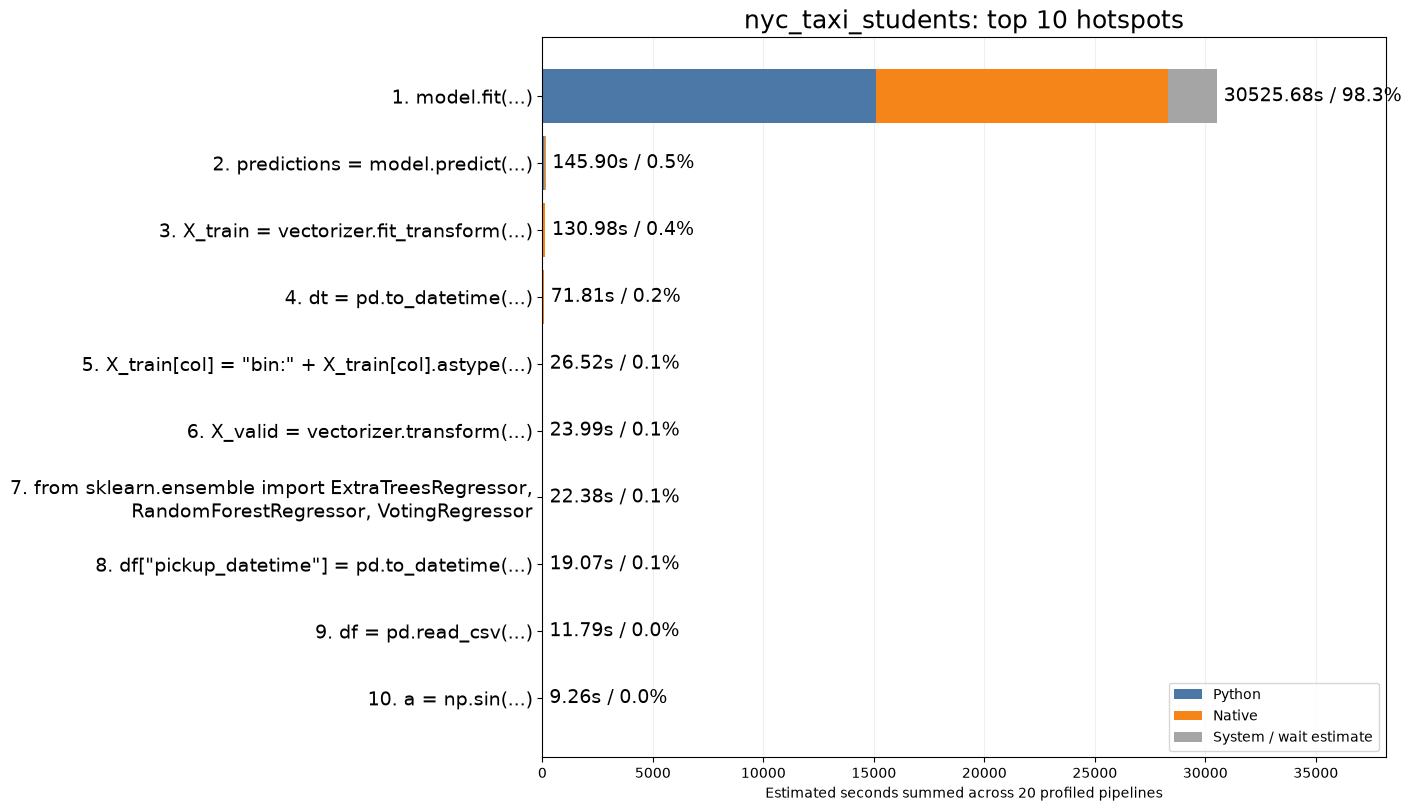

In [4]:
analyses = report_hotspot.analyze_all(TRAJECTORIES, top_n=TOP_N)
top10_details_by_trajectory = {}
for name, analysis in analyses.items():
    details = report_hotspot.top10_details(analysis)
    top10_details_by_trajectory[name] = details
    output_dir = ROOT / "results" / name
    output_dir.mkdir(parents=True, exist_ok=True)
    analysis.operation_summary.to_csv(output_dir / "hotspots.csv", index=False)
    details.to_csv(output_dir / "hotspots_details.csv", index=False)
    display(Markdown(f"### {name}"))
    report_hotspot.report_trajectory(analysis)
    display(analysis.top10.round(3))
    fig = report_hotspot.plot_hotspots({name: analysis}, output_dir / "hotspots.png")
    display(fig)
    plt.close(fig)

# Preserve the original Spaceship Titanic aliases for interactive exploration.
spaceship = analyses["spaceship_titanic_students"]
house_price = analyses["house_price_students"]
nyc_housing = analyses["nyc_housing_students"]
nyc_taxi = analyses["nyc_taxi_students"]
line_details, runs = spaceship.line_details, spaceship.runs
operation_summary, top10 = spaceship.operation_summary, spaceship.top10
trajectory_profile_s = spaceship.profile_s
top10_details = top10_details_by_trajectory["spaceship_titanic_students"]


## Report overview

Shares below use each trajectory's summed profiled elapsed time. Category shares can differ from 100% because sampling attribution may leave a residual. The trajectories have different data, models, and workload sizes; their total durations are not a controlled performance comparison.

In [5]:
overview = []
for name, analysis in analyses.items():
    category_seconds = categories_by_trajectory[name].groupby("category")["total_s"].sum()
    overview.append({
        "trajectory": name,
        "pipelines": len(analysis.runs),
        "profile_s": analysis.profile_s,
        "top_10_share_pct": analysis.top10.share_of_runs_pct.sum(),
        **{f"{category}_pct": category_seconds[category] / analysis.profile_s * 100
           for category in report_categories.CATEGORIES},
    })
report_overview = pd.DataFrame(overview).set_index("trajectory")
report_overview.to_csv(ROOT / "results/report_overview.csv")
display(report_overview.round(3))


,pipelines,profile_s,top_10_share_pct,setup_pct,data handling_pct,models_pct,other_pct
trajectory,,,,,,,
spaceship_titanic_students,25,75.071,89.569,34.098,12.426,51.570,1.235
house_price_students,19,980.792,83.272,0.382,31.512,68.089,0.000
nyc_housing_students,20,1022.085,33.347,0.766,95.610,3.177,0.423
nyc_taxi_students,20,31055.129,99.782,0.121,1.093,98.773,0.013


## Traceable hotspot details

Every source location behind Top N is retained, including locations with zero sampled time. `n_pipelines` counts source presence, not just timed execution. Select any trajectory below; filter the full table by rank or pipeline to inspect a candidate.

In [6]:
DETAIL_TRAJECTORY = "nyc_taxi_students"
details = top10_details_by_trajectory[DETAIL_TRAJECTORY]
display(details.drop(columns=["source_file", "source"]).head(30).round(4))
# Examples:
# details.query("rank == 1")
# top10_details_by_trajectory["nyc_housing_students"].query("pipeline == 'pipeline_1_1'")


,rank,pipeline,location,lineno,operation,modules,python_s,native_s,system_s,total_s
0,1,pipeline_7_1,trajectories/nyc_taxi_students/pipeline_7_1.py...,148,"model.fit(X_train, y_train)",sklearn.base,1927.8788,1133.8140,178.0685,3239.7613
1,1,pipeline_4_3,trajectories/nyc_taxi_students/pipeline_4_3.py...,123,"model.fit(X_train, y_train)",sklearn.base,1725.9742,1141.0849,152.9949,3020.0540
2,1,pipeline_7_2,trajectories/nyc_taxi_students/pipeline_7_2.py...,148,"model.fit(X_train, y_train)",sklearn.base,1535.3591,785.7302,107.9116,2429.0010
3,1,pipeline_5_3,trajectories/nyc_taxi_students/pipeline_5_3.py...,108,"model.fit(X_train, y_train)",sklearn.base,1747.7263,118.6340,558.0458,2424.4061
4,1,pipeline_3_3,trajectories/nyc_taxi_students/pipeline_3_3.py...,125,"model.fit(X_train, y_train)",sklearn.base,1841.2658,188.8393,339.3152,2369.4203
5,1,pipeline_4_1,trajectories/nyc_taxi_students/pipeline_4_1.py...,123,"model.fit(X_train, y_train)",sklearn.base,1501.2364,452.7851,136.8720,2090.8935
6,1,pipeline_6_3,trajectories/nyc_taxi_students/pipeline_6_3.py...,117,"model.fit(X_train, y_train)",sklearn.base,1181.3855,790.9777,117.6784,2090.0416
7,1,pipeline_2_3,trajectories/nyc_taxi_students/pipeline_2_3.py:95,95,"model.fit(X_train, y_train)",sklearn.base,8.5171,1592.6988,19.7613,1620.9772
8,1,pipeline_4_2,trajectories/nyc_taxi_students/pipeline_4_2.py...,123,"model.fit(X_train, y_train)",sklearn.base,934.6951,576.6051,78.7548,1590.0549
9,1,pipeline_1_3,trajectories/nyc_taxi_students/pipeline_1_3.py...,104,"model.fit(X_train, y_train)",sklearn.base,8.7725,1340.0084,14.8774,1363.6583


## Interpretation and next experiments

- **Spaceship Titanic:** training and first-time library imports dominate the leading statements. Check model and fold identity before proposing reuse.
- **House Price:** model fitting and CSV loading lead the ranking. Evaluate data-loading reuse and training improvements separately.
- **NYC Housing:** the leading source statements include parquet loading and sampling. Examine repeated table reads and transformations; a sampled row subset does not eliminate the cost of reading the original tables.
- **NYC Taxi:** `model.fit(X_train, y_train)` accounts for approximately 98.3% of summed profiled runtime in this dataset. It combines different estimators, feature branches, and folds; it is not one reusable computation.

These are priorities for investigation, not measured speedups. Validate any changes with repeated unprofiled runs and predictive-quality checks. System time is not a direct disk-I/O measurement, and Python/native shares alone do not prove that parallelism or vectorization will help.
